![Banner](../images/09_07_banner_rs_texture.png)


# Texture Analysis of Landsat Imagery: Local Pattern-Based Methods (LBP)

Local pattern methods describe texture as a vocabulary of tiny micro-patterns (spots, edges, corners, line ends, flat areas) and characterize a region by how often each pattern occurs.


## Overview

The Local Binary Pattern (LBP) operator is the best-known example: it is simple, fast, invariant to monotonic changes in brightness and, in its uniform form, invariant to rotation. This notebook explains the theory of LBP and its variants, computes it on the NIR band of a Landsat 9 scene over Las Vegas with `geolattice.rsense.texture`, explores its parameters, and shows where it works well and where it does not.


### Image texture in brief

Spectral values tell us *what* a pixel is made of; **texture** tells us *how pixel values are arranged*
around it. Texture is the spatial variation of gray levels inside a neighbourhood and describes
properties such as smoothness, coarseness, regularity, directionality and contrast. Haralick,
Shanmugam and Dinstein (1973) noted that tone and texture are always present together in an image, but
one may dominate the other depending on the scene.

At Landsat's 30 m resolution many land-cover classes overlap spectrally: urban fabric, bare soil and
rock are all bright and dry in an arid scene; crop types or forest stands can share the same NDVI;
rough terrain mixes lit slopes and shadow within a few pixels. Texture separates such classes because
it responds to *pattern*, not only to *brightness*, and texture layers are routinely stacked with bands
and indices as predictors in land-cover classification, urban mapping, forest-structure modelling and
soil mapping.

Methods are usually grouped into six families. This series covers them in five notebooks:

| Notebook | Family | Methods |
|---|---|---|
| 09_07_01 | [Statistical and structural texture](09_07_01_texture_analysis_of_landsat_imagery_statistical_and_structural_methods.ipynb) | First-order statistics, GLCM, GLRLM, edge density, lacunarity |
| 09_07_02 | [Transform-based (spectral) texture](09_07_02_texture_analysis_of_landsat_imagery_transform_based_spectral_methods.ipynb) | Fourier power spectrum, Gabor filter bank, Haar wavelets |
| 09_07_03 | **Local pattern-based texture** (this notebook) | Local Binary Patterns (LBP) |
| 09_07_04 | [Model-based texture](09_07_04_texture_analysis_of_landsat_imagery_model_based_methods.ipynb) | Markov Random Field energy, fractal dimension, autoregressive model |
| 09_07_05 | [Deep-learning-based texture](09_07_05_texture_analysis_of_landsat_imagery_deep_learning_based_methods.ipynb) | Pretrained CNN feature maps |

All methods come from `geolattice.rsense.texture`. Every function accepts a 2-D `xr.DataArray` (or NumPy
array) and returns a georeferenced result with the same shape as the input; inputs with leading
dimensions (band, time, polarization) are processed slice by slice, and multi-feature methods return an
`xr.Dataset` with one variable per feature.


### Theory: Local Binary Patterns

**The basic operator.** Ojala, Pietikäinen and Harwood (1996) proposed describing the neighbourhood of a
pixel $g_c$ by thresholding its $P$ neighbours $g_p$, sampled on a circle of radius $R$, at the value of
the centre:

$$\mathrm{LBP}_{P,R} = \sum_{p=0}^{P-1} s(g_p - g_c)\,2^p,\qquad s(z) = \begin{cases}1 & z \ge 0\\ 0 & z < 0.\end{cases}$$

Neighbours that do not fall on pixel centres are bilinearly interpolated. With $P = 8$ the code is an
8-bit number between 0 and 255, one per pixel. Because only the **sign** of each difference is kept, LBP
is invariant to any monotonic change of gray scale (illumination, gain, offset, contrast stretch).

**Rotation invariance (`ror`).** Rotating the image rotates the bit string. Taking the minimum over all
circular bit rotations, $\mathrm{LBP}^{ri} = \min_k \mathrm{ROR}(\mathrm{LBP}, k)$, maps all rotated
versions of a pattern to one code (36 codes for $P = 8$).

**Uniform patterns (`uniform`).** Ojala, Pietikäinen and Mäenpää (2002) observed that most codes in
natural textures have at most two 0/1 transitions around the circle. These **uniform** patterns are the
fundamental micro-structures:

| Uniform code | Bit string (example) | Micro-structure |
|---|---|---|
| 0 | 00000000 | Bright spot / local maximum seen from the neighbours (all darker) |
| 1-7 | 00000001 ... 01111111 | Edges and corners of different curvature (number of 1 bits) |
| 8 | 11111111 | Dark spot or flat area (all neighbours ≥ centre) |
| 9 (= P + 1) | e.g. 01010101 | Every non-uniform (noisy, irregular) pattern |

The rotation-invariant uniform operator $\mathrm{LBP}^{riu2}_{P,R}$ has only $P + 2$ codes, which makes
its histogram compact and statistically stable.

**Contrast (`var`).** LBP ignores contrast by design. The companion operator
$\mathrm{VAR}_{P,R} = \frac{1}{P}\sum_p (g_p - \bar g)^2$ measures it, and the joint distribution
LBP/VAR is a powerful descriptor.

**From codes to texture features.** A texture is the **histogram** of codes inside a window $W$. With
$h_k$ the share of pixels with code $k$, `geolattice.rsense` summarizes it as

$$\text{uniformity} = \sum_k h_k^2,\qquad \text{entropy} = -\sum_k h_k \log_2 h_k.$$

High uniformity means one micro-pattern dominates (a repetitive surface); high entropy means many
patterns are mixed (a heterogeneous surface). The maximum entropy for $P = 8$ uniform codes is
$\log_2 10 = 3.32$ bits.

**Scale.** $R$ sets the distance at which neighbours are compared, and $P$ the angular resolution.
Common choices are (8, 1), (16, 2) and (24, 3); combining several radii gives a multi-resolution LBP.


### Strengths, limits and applications

| | |
|---|---|
| **Strengths** | Very fast; invariant to monotonic gray-scale change and (uniform form) to rotation; few parameters; histogram features are robust and compact |
| **Limits** | Ignores contrast; sensitive to noise on smooth surfaces, because a tiny difference flips a bit; micro-patterns at 30 m are often mixtures rather than objects |

| Application | Typical setting |
|---|---|
| Building and impervious-surface detection in high-resolution imagery | LBP histograms of 0.3-2 m images |
| Scene classification of aerial and satellite image tiles | Multi-radius LBP histograms as tile descriptors |
| SAR sea-ice and land-cover classification | LBP is insensitive to calibration and incidence-angle gain |
| Tree-crown and orchard mapping from UAV images | Uniform LBP at the crown scale |
| Change detection | Comparing LBP histograms of two dates, robust to radiometric differences |
| Medical images, faces and materials (outside remote sensing) | The original application domains of LBP |


### Learning objectives

1. Compute an LBP code by hand and explain uniform, rotation-invariant and variance operators.
2. Compute LBP code maps and LBP histogram features on Landsat NIR with `geolattice.rsense.texture`.
3. Explore the effect of radius, number of neighbours, window size and gray levels.
4. Explain why LBP is sensitive to noise on smooth surfaces, and reduce that sensitivity.
5. Compare LBP signatures of three surfaces and test what LBP adds to an unsupervised classification.


### Data

| File | Content |
|---|---|
| `data/blue.tif` | Landsat 9 OLI-2 band 2 (blue), Collection 2 Level-2 surface reflectance DN |
| `data/green.tif` | Landsat 9 OLI-2 band 3 (green) |
| `data/red.tif` | Landsat 9 OLI-2 band 4 (red) |
| `data/nir.tif` | Landsat 9 OLI-2 band 5 (NIR) |

All four bands come from the Las Vegas scene used in the Landsat module
([09_02_04_landsat_half_a_century_of_earth_observation](../09_02_optical/09_02_04_landsat_half_a_century_of_earth_observation.ipynb)): path 39, row 35, 8 July 2024, UTM zone
11N (EPSG:32611), 30 m, 1,679 × 1,512 pixels, stored as unsigned 16-bit DN with 0 as the fill value.


### Contents

1. Setup
2. Loading the Landsat bands and the study window
3. A worked LBP example
4. LBP code maps
5. LBP texture features
6. Parameters: radius, neighbours, window and gray levels
7. LBP, contrast and noise
8. Application: texture signatures and clustering
9. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: silence noisy warnings, import the libraries and choose the array backend.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. 'mean of empty slice' in all-NaN windows
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices from pandas and xarray

import time  # time each texture computation
from pathlib import Path  # portable file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters (DataArray, Dataset)
import rasterio  # GeoTIFF reading and writing
import matplotlib.pyplot as plt  # figures
from matplotlib.patches import Rectangle  # draw the study-window rectangle

import geolattice.rsense as rs  # GeoLattice remote sensing: reading, scaling and plotting
from geolattice.rsense import texture as tx  # GeoLattice texture functions

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 90})  # figure resolution
# "cpu" keeps every array on NumPy; the texture functions copy GPU arrays to the CPU anyway.
# report the GeoLattice version and switch to the NumPy (CPU) backend
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))

geolattice.rsense 0.3.49 | backend: cpu


## Loading the Landsat bands and the study window

The files hold raw Collection 2 Level-2 digital numbers (DN). We read them with `rs.read`, put them in
one `xr.Dataset`, and convert them to surface reflectance with `rs.optical.scale`, which applies
**reflectance = DN × 0.0000275 − 0.2** and turns the fill value 0 into NaN.

Window-based texture is easier to see, and much faster to compute, on a smaller area. We work on a
512 × 512 pixel window (15.4 × 15.4 km) on the eastern edge of Las Vegas that contains four very
different surfaces:

- the regular **street grid** of the city (west),
- the smooth, bare **alluvial fan** below Frenchman Mountain (centre),
- the folded sedimentary **ridges of Frenchman Mountain** (east),
- the vegetated channel of the **Las Vegas Wash** (south), red in colour infrared.


In [2]:
# 1. Read each band as a 2-D DataArray (drop the singleton "band" dimension).
DATA = Path("../../../../Data/00_shared/data_remote_sensing/landsat9_vegas_20240708/LC09_L2SP_039035_20240708_02_T1")  # Landsat 9 scene, path 39 row 35, 8 July 2024
BANDS = ["blue", "green", "red", "nir"]  # the four bands used in this notebook
# read each band; masked=False keeps the raw digital numbers (DN)
ls_dn = xr.Dataset({b: rs.read(DATA / f"{b}.tif", masked=False).squeeze("band", drop=True)
                    for b in BANDS})  # one variable per band
ls_dn = ls_dn.rio.write_crs(ls_dn["red"].rio.crs)  # store the CRS on the Dataset as a whole

# 2. Scale DN to surface reflectance (fill value 0 becomes NaN) and clip to [1e-4, 1].
# Landsat Collection 2 scale and offset: DN -> reflectance
ls = rs.optical.scale(ls_dn, sensor="landsat").clip(min=1e-4, max=1.0)
# scene size, pixel size and CRS
print(f"{ls.rio.width} x {ls.rio.height} pixels at {ls.rio.resolution()[0]:.0f} m, CRS {ls.rio.crs}")

# 3. Study window (rows/columns in the full scene) and the NIR band used for most texture measures.
WIN = dict(y=slice(500, 1012), x=slice(900, 1412))  # 512 x 512 pixel window (rows 500-1011, columns 900-1411)
sub = ls.isel(WIN)  # all four bands inside the window
nir = sub["nir"]  # the NIR band of the window

1679 x 1512 pixels at 30 m, CRS EPSG:32611


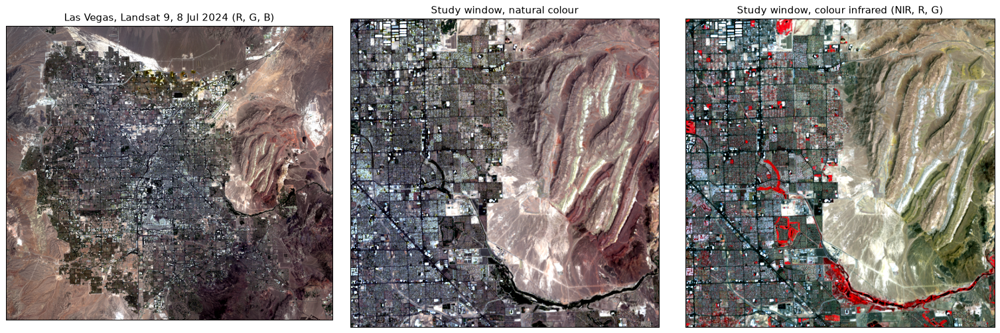

In [3]:
# Where the study window lies, and how it looks in natural colour and colour infrared.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))  # three panels side by side
# full scene, red-green-blue
rs.viz.plot_rgb(ls, "true_color", ax=axes[0], title="Las Vegas, Landsat 9, 8 Jul 2024 (R, G, B)")
# the study window in yellow (x = column 900, y = row 500)
axes[0].add_patch(Rectangle((900, 500), 512, 512, fill=False, ec="yellow", lw=2))
# the window in natural colour
rs.viz.plot_rgb(sub, "true_color", ax=axes[1], title="Study window, natural colour")
# NIR, red, green: vegetation appears red
rs.viz.plot_rgb(sub, "false_color", ax=axes[2], title="Study window, colour infrared (NIR, R, G)")
for a in axes:  # hide the pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

## A worked LBP example

A 3 × 3 neighbourhood with centre 50. Neighbours are read counter-clockwise starting from the right-hand
neighbour, which is the convention of `scikit-image` for P = 8, R = 1.


In [4]:
from skimage.feature import local_binary_pattern  # scikit-image LBP, to check the hand computation

block = np.array([[60, 70, 65],  # a 3 x 3 neighbourhood of gray values
                  [40, 50, 30],
                  [45, 42, 20]], dtype=float)
gc = block[1, 1]  # the centre pixel g_c
# Offsets (row, col) for p = 0..7 on a circle of radius 1, counter-clockwise from the right.
offs = [(0, 1), (-1, 1), (-1, 0), (-1, -1), (0, -1), (1, -1), (1, 0), (1, 1)]
gp = np.array([block[1 + dy, 1 + dx] for dy, dx in offs])  # the eight neighbours g_p in that order
bits = (gp >= gc).astype(int)  # s(g_p - g_c): 1 if the neighbour is at least as bright as the centre
code = int((bits * 2 ** np.arange(8)).sum())  # LBP code = sum of bit_p x 2^p
# number of 0/1 changes around the circle (np.roll compares each bit with the previous one)
transitions = int(np.sum(bits != np.roll(bits, 1)))

print("neighbours g_p :", gp.astype(int))  # the neighbours
print("bits s(g_p-g_c):", bits)  # their bits
# a code with at most two transitions is 'uniform'
print(f"LBP code = {code}, 0/1 transitions = {transitions} -> {'uniform' if transitions <= 2 else 'non-uniform'}")
for m in ["default", "ror", "uniform"]:  # three scikit-image variants
    # pad by one pixel so the centre (now at [2, 2]) has a full neighbourhood
    print(f"scikit-image {m:8s}:", int(local_binary_pattern(np.pad(block, 1, mode="edge"), 8, 1, method=m)[2, 2]))

neighbours g_p : [30 65 70 60 40 45 42 20]
bits s(g_p-g_c): [0 1 1 1 0 0 0 0]
LBP code = 14, 0/1 transitions = 2 -> uniform
scikit-image default : 14
scikit-image ror     : 7
scikit-image uniform : 3


The three brighter neighbours (upper-right, up, upper-left) form a single run of ones, so the bit
string has two 0/1 transitions and the pattern is **uniform**: a horizontal edge with the bright side
above. Its rotation-invariant uniform code is the number of 1 bits (3). The `default` code (14) depends
on where the bright side lies; the `ror` and `uniform` codes would be the same if the block were rotated.
Changing one neighbour so that the ones are split into two runs would make the pattern non-uniform
(code 9).

### The ten uniform patterns (P = 8)


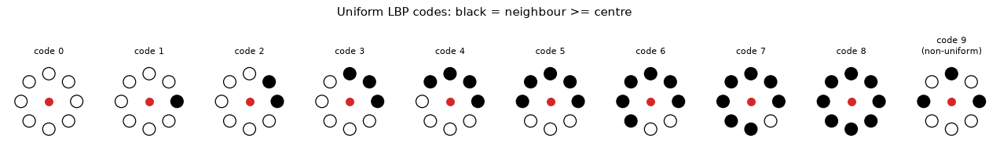

In [5]:
fig, axes = plt.subplots(1, 10, figsize=(18, 2.3))  # ten small panels
ang = np.arange(8) * np.pi / 4  # angles of the eight neighbours
for k, ax in enumerate(axes):  # one panel per code
    if k <= 8:  # codes 0-8: k consecutive ones
        b = np.r_[np.ones(k), np.zeros(8 - k)]  # k ones followed by 8 - k zeros
    else:  # the tenth panel: a pattern with more than two transitions
        b = np.array([1, 0, 1, 0, 1, 0, 0, 0])  # non-uniform example
    # the neighbours, black where the bit is 1
    ax.scatter(np.cos(ang), np.sin(ang), c=b, cmap="gray_r", vmin=0, vmax=1, s=160, edgecolors="k")
    ax.scatter(0, 0, c="tab:red", s=60)  # the centre pixel
    ax.set_title(f"code {k}" + ("\n(non-uniform)" if k == 9 else ""), fontsize=9)  # panel title
    # same scale in every panel, no axes
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal"); ax.axis("off")
plt.suptitle("Uniform LBP codes: black = neighbour >= centre", y=1.08)  # overall title
plt.show()  # draw

## LBP code maps

LBP codes are computed per pixel. `geolattice.rsense` first rescales the band to `levels` integer gray levels
(256 by default) so that floating-point noise does not create spurious patterns; the code map below
does the same.


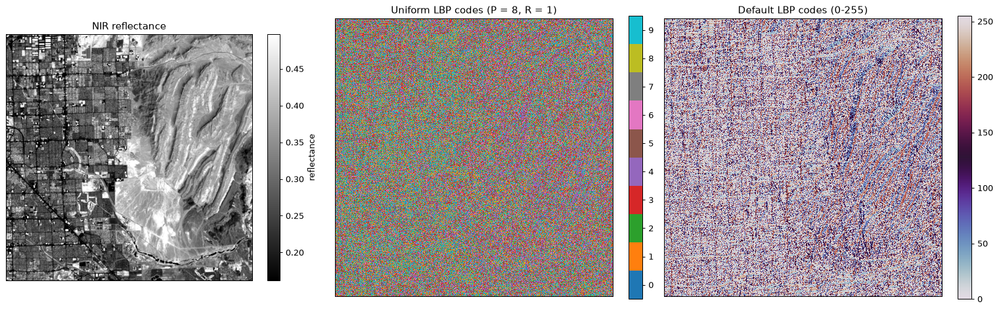

In [6]:
def to_levels(a, levels=256):  # rescale an array to integers 0 .. levels-1 (LBP needs an integer image)
    a = np.nan_to_num(a, nan=np.nanmean(a))  # NaN -> mean
    # min-max scaling, clipped and cast to uint8
    return np.clip((a - a.min()) / (a.max() - a.min()) * (levels - 1), 0, levels - 1).astype("uint8")

q8 = to_levels(nir.values)  # NIR as 256 gray levels
codes = local_binary_pattern(q8, 8, 1, method="uniform")  # uniform, rotation-invariant codes 0-9 (P = 8, R = 1)
codes_def = local_binary_pattern(q8, 8, 1, method="default")  # plain 8-bit codes 0-255

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))  # three panels
rs.viz.plot_raster(nir, ax=axes[0], cmap="gray", title="NIR reflectance")  # the NIR image
# one colour per uniform code
im = axes[1].imshow(codes, cmap="tab10", vmin=-0.5, vmax=9.5, interpolation="nearest")
# colour bar with the ten codes, and title
plt.colorbar(im, ax=axes[1], ticks=range(10), fraction=0.046); axes[1].set_title("Uniform LBP codes (P = 8, R = 1)")
im = axes[2].imshow(codes_def, cmap="twilight", interpolation="nearest")  # default codes in a cyclic colour map
# colour bar and title
plt.colorbar(im, ax=axes[2], fraction=0.046); axes[2].set_title("Default LBP codes (0-255)")
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

At 30 m the uniform-code map looks like noise everywhere: neighbouring pixels flip between codes, and
the street grid and the ridges are barely visible. The default (0-255) codes show the ridge lines
faintly, because their bit patterns depend on orientation.


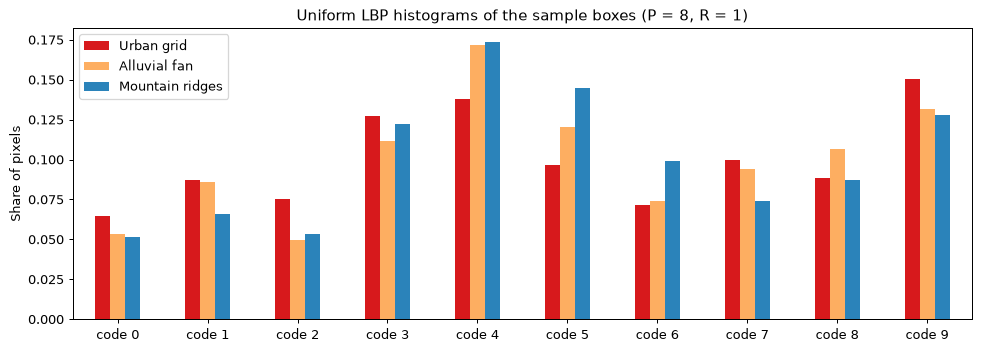

,code 0,code 1,code 2,code 3,code 4,code 5,code 6,code 7,code 8,code 9
Urban grid,6.4%,8.8%,7.5%,12.8%,13.8%,9.7%,7.1%,10.0%,8.9%,15.1%
Alluvial fan,5.3%,8.6%,4.9%,11.2%,17.2%,12.1%,7.4%,9.4%,10.7%,13.2%
Mountain ridges,5.1%,6.6%,5.3%,12.2%,17.4%,14.5%,9.9%,7.4%,8.8%,12.8%


In [7]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

# Uniform-LBP histogram of each sample box.
# share of each code 0-9 among the 1,600 pixels of each box
hists = pd.DataFrame({name: np.bincount(codes[ys, xs].astype(int).ravel(), minlength=10) / 1600
                      # one column per box, one row per code
                      for name, (ys, xs) in BOXES.items()}, index=[f"code {k}" for k in range(10)])
# grouped bars in the box colours
ax = hists.plot(kind="bar", figsize=(11, 4), color=[COLORS[c] for c in hists.columns], rot=0)
ax.set(ylabel="Share of pixels", title="Uniform LBP histograms of the sample boxes (P = 8, R = 1)")  # labels
plt.tight_layout(); plt.show()  # arrange and draw
# show as percentages
hists.T.map(lambda v: f"{v:.1%}")

The three surfaces have very similar code histograms. Non-uniform patterns (code 9) make up 13% to 15%
everywhere. The city has slightly more spots and corners (codes 0 to 3) and the natural surfaces slightly
more edge codes (4 and 5), but the differences are a few percentage points.


## LBP texture features

`tx.lbp_texture(img, radius, n_points, method, size, step, levels, features)` computes the code map,
builds the code histogram of every `size` × `size` window (every `step` pixels) and returns
`lbp_uniformity` and/or `lbp_entropy`, resampled to full resolution.


lbp_texture: 0.8 s -> ['lbp_uniformity', 'lbp_entropy']


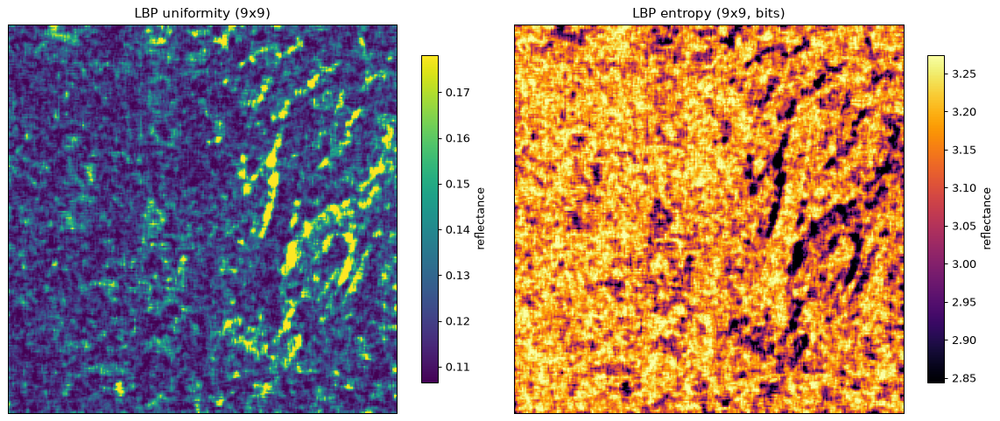

In [8]:
t0 = time.time()  # start the timer
# uniformity and entropy of the code histogram in 9 x 9 windows
lbp = tx.lbp_texture(nir, radius=1, n_points=8, method="uniform", size=9, step=2)
print(f"lbp_texture: {time.time() - t0:.1f} s ->", list(lbp.data_vars))  # run time and layer names

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))  # two panels
# share of uniform codes
rs.viz.plot_raster(lbp["lbp_uniformity"], ax=axes[0], cmap="viridis", title="LBP uniformity (9x9)")
# entropy of the code histogram
rs.viz.plot_raster(lbp["lbp_entropy"], ax=axes[1], cmap="inferno", title="LBP entropy (9x9, bits)")
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

LBP entropy varies only between about 2.85 and 3.27 bits, close to the maximum of 3.32, everywhere in
the window. The only clear structures are the ridge lines, where consistent edge patterns lower the
entropy. The city and the fan look alike, unlike every texture map in notebooks 09_07_01 and 09_07_02.


## Parameters: radius, neighbours, window and gray levels

### Radius and number of neighbours

Larger radii compare pixels farther apart and capture coarser micro-structure. The number of uniform
codes grows with P, so entropy values are not comparable between settings; compare their spatial
pattern instead.


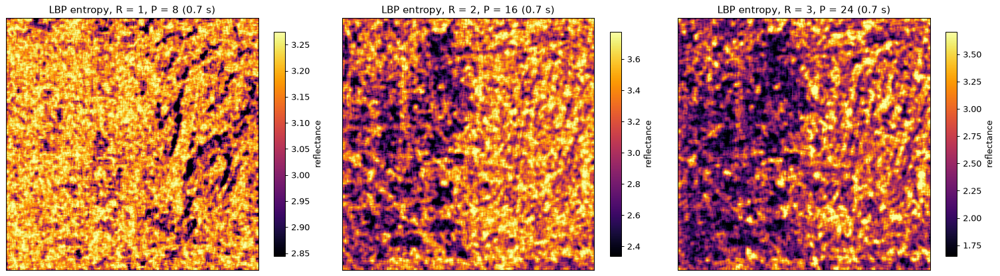

,"R=1, P=8","R=2, P=16","R=3, P=24"
Urban grid,3.183,3.137,2.605
Alluvial fan,3.121,3.297,2.771
Mountain ridges,3.113,3.442,3.101


In [9]:
settings = [(1, 8), (2, 16), (3, 24)]  # (radius, number of neighbours) pairs
fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
ent = {}  # entropy maps by setting
for ax, (r, p) in zip(axes, settings):  # loop over the settings
    t0 = time.time()  # time each setting
    # entropy only
    l = tx.lbp_texture(nir, radius=r, n_points=p, method="uniform", size=9, step=2, features=("entropy",))
    ent[f"R={r}, P={p}"] = l["lbp_entropy"]  # keep the map
    rs.viz.plot_raster(l["lbp_entropy"], ax=ax, cmap="inferno",  # draw it with the run time in the title
                       title=f"LBP entropy, R = {r}, P = {p} ({time.time() - t0:.1f} s)")
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

# mean entropy in each box for each setting
pd.DataFrame({k: {name: float(v.isel(y=ys, x=xs).mean()) for name, (ys, xs) in BOXES.items()}
              for k, v in ent.items()}).round(3)  # columns = settings

The radius changes what LBP sees. At R = 1 the city has the highest entropy; at R = 2 and R = 3 the
ridges do, and the city has the lowest at R = 3, where neighbours 90 m away often fall on the same
block or street. Compare spatial patterns, not absolute values: the number of codes changes with P.


### Window size


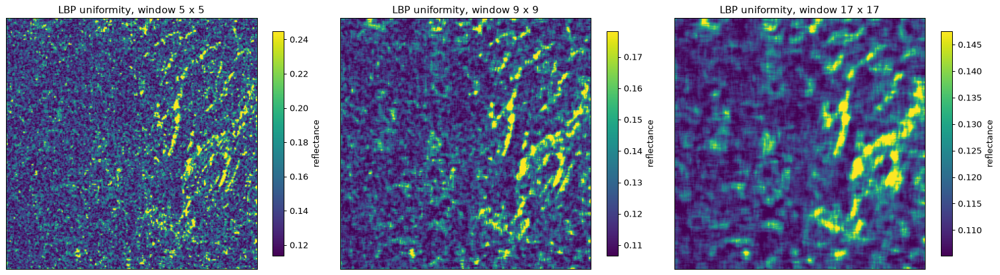

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three window sizes
for ax, s in zip(axes, [5, 9, 17]):  # 5, 9 and 17 pixels
    l = tx.lbp_texture(nir, size=s, step=2, features=("uniformity",))  # uniformity only
    # draw it
    rs.viz.plot_raster(l["lbp_uniformity"], ax=ax, cmap="viridis", title=f"LBP uniformity, window {s} x {s}")
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

Larger windows give smoother, more stable uniformity maps but do not create contrast that the codes do
not have: the pattern is the same at every window size.


### Gray levels

Because LBP keeps only the sign of differences, coarser quantization merges nearly equal neighbours into
"equal" (which counts as ≥, bit 1). Fewer levels therefore act as a noise threshold.


In [11]:
rows = {}  # one column per number of gray levels
for lv in [16, 64, 256, 1024]:  # quantise NIR to 16 ... 1024 levels before the LBP
    l = tx.lbp_texture(nir, size=9, step=2, levels=lv)  # LBP features at this quantisation
    # mean entropy in each box
    rows[f"{lv} levels"] = {name: float(l["lbp_entropy"].isel(y=ys, x=xs).mean()) for name, (ys, xs) in BOXES.items()}
# fewer levels make small differences count as 'equal'
pd.DataFrame(rows).round(3)

,16 levels,64 levels,256 levels,1024 levels
Urban grid,2.710,3.137,3.183,3.190
Alluvial fan,1.692,2.909,3.121,3.142
Mountain ridges,1.820,2.959,3.113,3.119


Quantization matters much more than the window. At 256 or 1,024 levels the three surfaces have almost
the same entropy. At 16 levels, small reflectance differences become "equal", noise patterns collapse
into the flat code, and the entropy separates the city (2.71) from the fan (1.69) and the ridges (1.82).
Coarse quantization acts as a noise threshold.


## LBP, contrast and noise

LBP treats a 0.0001 reflectance difference exactly like a 0.1 difference. On the smooth alluvial fan the
differences between neighbours are close to the sensor noise, so the bits are close to random and the
fan produces as many micro-patterns as the city. Three possible remedies:

1. **Add contrast back** with the variance operator $\mathrm{VAR}_{P,R}$ (`method="var"` in
   `scikit-image`), pooled in a window.
2. **Quantize to fewer gray levels** (see *Parameters*), so that small differences become "equal".
3. **Suppress noise** before computing LBP with a small Gaussian filter.


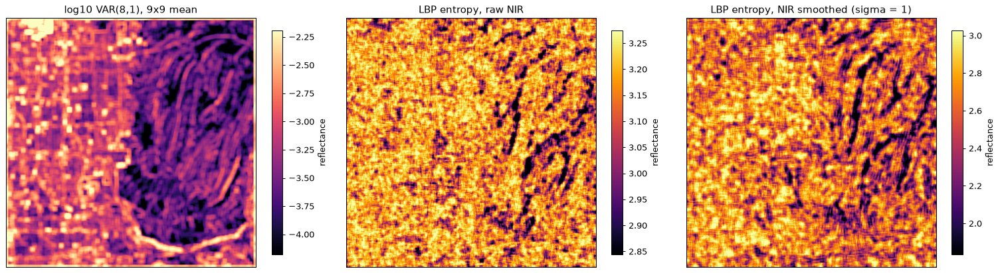

,"LBP entropy, raw","LBP entropy, smoothed",log10 VAR
Urban grid,3.183,2.606,-2.789
Alluvial fan,3.121,2.585,-3.577
Mountain ridges,3.113,2.339,-3.555


In [12]:
from scipy.ndimage import gaussian_filter  # smoothing
from scipy.ndimage import uniform_filter  # moving-window mean

# 1. Rotation-invariant local variance VAR(8, 1), pooled in a 9 x 9 window.
# VAR: local variance of the 8 neighbours (contrast that LBP ignores)
var_map = local_binary_pattern(nir.fillna(float(nir.mean())).values, 8, 1, method="var")
# mean VAR in 9 x 9 windows, as a DataArray on the NIR grid
lbp_var = nir.copy(data=uniform_filter(np.nan_to_num(var_map), 9))

# 2. LBP entropy after light Gaussian smoothing (sigma = 1 pixel).
# NIR smoothed by a Gaussian of sigma 1 pixel
nir_s = nir.copy(data=gaussian_filter(nir.fillna(float(nir.mean())).values, 1.0))
lbp_s = tx.lbp_texture(nir_s, size=9, step=2)  # LBP features of the smoothed image

fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
# VAR on a log scale
rs.viz.plot_raster(np.log10(lbp_var + 1e-10), ax=axes[0], cmap="magma", title="log10 VAR(8,1), 9x9 mean")
# entropy of the raw image
rs.viz.plot_raster(lbp["lbp_entropy"], ax=axes[1], cmap="inferno", title="LBP entropy, raw NIR")
# entropy after smoothing
rs.viz.plot_raster(lbp_s["lbp_entropy"], ax=axes[2], cmap="inferno", title="LBP entropy, NIR smoothed (sigma = 1)")
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

# box means of the three measures
pd.DataFrame({"LBP entropy, raw": {n: float(lbp["lbp_entropy"].isel(y=ys, x=xs).mean()) for n, (ys, xs) in BOXES.items()},
              # smoothing removes noise patterns
              "LBP entropy, smoothed": {n: float(lbp_s["lbp_entropy"].isel(y=ys, x=xs).mean()) for n, (ys, xs) in BOXES.items()},
              # contrast
              "log10 VAR": {n: float(np.log10(lbp_var.isel(y=ys, x=xs).mean())) for n, (ys, xs) in BOXES.items()}}).round(3)

The variance operator separates the city from the natural surfaces clearly: log10 VAR is −2.79 in the
city against −3.58 on the fan and −3.56 on the ridges, about six times more variance. Gaussian smoothing
lowers LBP entropy everywhere but does not separate the city from the fan (2.61 against 2.59); only the
ridges, whose edges survive smoothing, stand out (2.34).


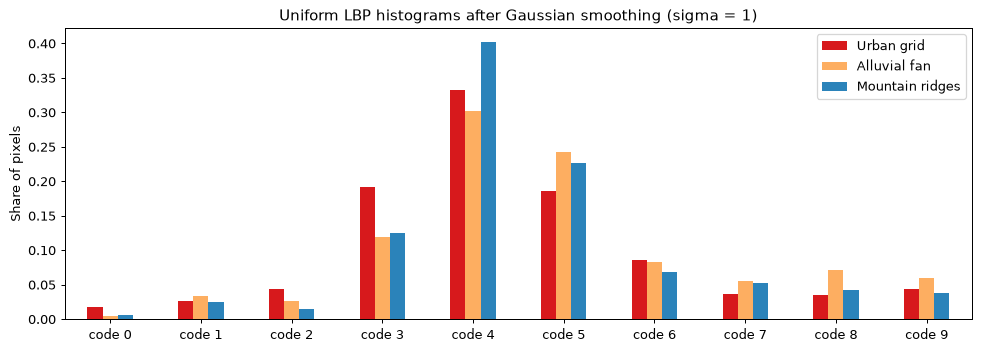

In [13]:
# Uniform-code histograms after smoothing: the fan loses its noise patterns.
# uniform codes of the smoothed NIR
codes_s = local_binary_pattern(to_levels(nir_s.values), 8, 1, method="uniform")
# code histogram of each box
hs = pd.DataFrame({name: np.bincount(codes_s[ys, xs].astype(int).ravel(), minlength=10) / 1600
                   for name, (ys, xs) in BOXES.items()}, index=[f"code {k}" for k in range(10)])  # rows = codes
ax = hs.plot(kind="bar", figsize=(11, 4), color=[COLORS[c] for c in hs.columns], rot=0)  # grouped bars
ax.set(ylabel="Share of pixels", title="Uniform LBP histograms after Gaussian smoothing (sigma = 1)")  # labels
plt.tight_layout(); plt.show()  # arrange and draw

After smoothing, the histograms are dominated by the edge codes 3 to 5, and non-uniform patterns drop
below 6%. The city keeps more code-3 patterns (corners), the ridges more code-4 patterns (straight
edges). Smoothing makes the codes cleaner but not much more distinctive at this resolution.


## Application: texture signatures and clustering


Three 40 × 40 pixel boxes (1.2 × 1.2 km), chosen by eye on the false-colour image, are used to compare
texture signatures:

| Box | Rows | Columns | Surface |
|---|---|---|---|
| Urban grid | 100-140 | 40-80 | Residential blocks and streets |
| Alluvial fan | 300-340 | 270-310 | Smooth bare desert soil |
| Mountain ridges | 130-170 | 400-440 | Folded sedimentary ridges of Frenchman Mountain |


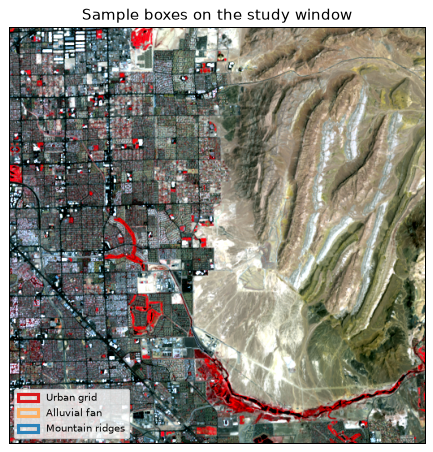

In [14]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes east of the city
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

fig, ax = plt.subplots(figsize=(6, 6))  # one panel
# colour infrared background
rs.viz.plot_rgb(sub, "false_color", ax=ax, title="Sample boxes on the study window")
for name, (ys, xs) in BOXES.items():  # draw each box
    # x = column start, y = row start, then width and height
    ax.add_patch(Rectangle((xs.start, ys.start), xs.stop - xs.start, ys.stop - ys.start,
                           # outline only, labelled for the legend
                           fill=False, ec=COLORS[name], lw=2.5, label=name))
ax.legend(loc="lower left", fontsize=8); ax.set_xticks([]); ax.set_yticks([])  # legend, no ticks
plt.show()  # draw

In [15]:
from sklearn.cluster import KMeans  # k-means clustering
from sklearn.preprocessing import StandardScaler  # standardise features to mean 0, std 1
from scipy.ndimage import generic_filter  # moving-window filter for the speckle measure

def box_means(ds):  # average feature values per sample box
    """Mean of every variable of `ds` inside each sample box."""
    # rows = features, columns = boxes
    return pd.DataFrame({name: {v: float(ds[v].isel(y=ys, x=xs).mean()) for v in ds.data_vars}
                         for name, (ys, xs) in BOXES.items()})

def plot_signatures(sig, title):  # compare the boxes feature by feature
    """Bar chart of box means, min-max scaled per feature across the three boxes."""
    # scale each feature to 0-1 across the three boxes
    norm = sig.sub(sig.min(axis=1), axis=0).div(sig.max(axis=1) - sig.min(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(norm)), 4.5))  # width grows with the number of features
    x = np.arange(len(norm))  # one group of bars per feature
    for k, name in enumerate(norm.columns):  # one bar per box, shifted sideways
        ax.bar(x + (k - 1) * 0.27, norm[name], width=0.27, color=COLORS[name], label=name)  # draw the bars
    ax.set_xticks(x, norm.index, rotation=45, ha="right")  # feature names, rotated
    ax.set(ylabel="Relative value (0 = lowest box, 1 = highest)", title=title)  # labels
    ax.legend(); plt.tight_layout(); plt.show()  # legend and draw

def kmeans_map(ds, k=5, n_fit=40000, seed=0):  # unsupervised map from a set of layers
    """Standardize the layers, fit k-means on a random pixel sample and label every pixel."""
    df = ds.to_dataframe(dim_order=["y", "x"])[list(ds.data_vars)]  # pixels as rows, layers as columns
    ok = df.notna().all(axis=1).values  # pixels without missing values
    X = StandardScaler().fit_transform(df[ok].values)  # standardise so every layer weighs the same
    rng = np.random.default_rng(seed)  # random sample generator
    # fit on at most 40,000 random pixels (faster)
    km = KMeans(k, n_init=10, random_state=seed).fit(X[rng.choice(len(X), min(n_fit, len(X)), replace=False)])
    lab = np.full(ok.size, np.nan); lab[ok] = km.predict(X)  # label all valid pixels; others stay NaN
    # labels back on the image grid
    return xr.DataArray(lab.reshape(ds.sizes["y"], ds.sizes["x"]), coords={"y": ds.y, "x": ds.x}, dims=("y", "x"))

def speckle(lab):  # how noisy a cluster map is
    """Share of pixels whose label differs from the majority label of their 3 x 3 neighbourhood."""
    a = np.nan_to_num(lab.values, nan=-1).astype(int)  # NaN -> -1 so the labels are integers
    # majority label in each 3 x 3 window
    mode = generic_filter(a, lambda v: np.bincount(v.astype(int) + 1).argmax() - 1, size=3)
    return float((a != mode).mean())  # share of pixels that differ from their neighbourhood majority

def box_purity(lab):  # how uniform each box is in a cluster map
    """Share of each box's pixels that fall in the box's most common cluster."""
    out = {}  # one value per box
    for name, (ys, xs) in BOXES.items():  # loop over the boxes
        v = lab.isel(y=ys, x=xs).values.ravel()  # labels inside the box
        v = v[np.isfinite(v)].astype(int)  # drop missing labels
        out[name] = np.bincount(v).max() / v.size  # share of the most common label
    return out  # dictionary box -> purity

# Spectral layers used as the baseline in every notebook: the four bands and NDVI.
# normalised difference vegetation index
ndvi = ((sub["nir"] - sub["red"]) / (sub["nir"] + sub["red"])).rename("NDVI")
spectral = xr.Dataset({**{b: sub[b] for b in BANDS}, "NDVI": ndvi})  # four bands plus NDVI

In [16]:
lbp_r2 = tx.lbp_texture(nir, radius=2, n_points=16, size=9, step=2)  # LBP with radius 2 and 16 neighbours
lbp16 = tx.lbp_texture(nir, size=9, step=2, levels=16)  # LBP of NIR quantised to 16 gray levels
lp_feats = xr.Dataset({  # the local-pattern layers of this notebook
    "LBP uniformity R1": lbp["lbp_uniformity"], "LBP entropy R1": lbp["lbp_entropy"],  # radius 1
    "LBP uniformity R2": lbp_r2["lbp_uniformity"], "LBP entropy R2": lbp_r2["lbp_entropy"],  # radius 2
    # after Gaussian smoothing
    "LBP entropy smoothed": lbp_s["lbp_entropy"], "LBP uniformity smoothed": lbp_s["lbp_uniformity"],
    # after coarse quantisation
    "LBP entropy 16 levels": lbp16["lbp_entropy"], "LBP uniformity 16 levels": lbp16["lbp_uniformity"],
    "log10 VAR": np.log10(lbp_var + 1e-10),  # local contrast
})
sig = box_means(lp_feats)  # mean of each feature in each box
# show the table
sig.round(4)

,Urban grid,Alluvial fan,Mountain ridges
LBP uniformity R1,0.1193,0.1281,0.1299
LBP entropy R1,3.1833,3.1207,3.1130
LBP uniformity R2,0.1935,0.1617,0.1389
LBP entropy R2,3.1370,3.2974,3.4420
LBP entropy smoothed,2.6055,2.5853,2.3386
LBP uniformity smoothed,0.2153,0.2129,0.2698
LBP entropy 16 levels,2.7096,1.6923,1.8198
LBP uniformity 16 levels,0.1940,0.4649,0.4084
log10 VAR,-2.8610,-3.7032,-3.6616


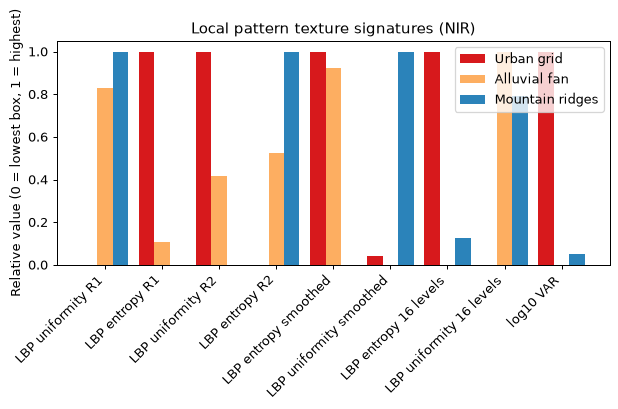

In [17]:
plot_signatures(sig, "Local pattern texture signatures (NIR)")  # bar chart of the box signatures

The 16-level LBP features and VAR give the clearest contrast between the city and the natural
surfaces. Raw R = 2 entropy and smoothed uniformity separate the ridges from the other two. The raw R = 1
features hardly differ between the boxes.


### Does this family add information? A clustering test

Texture is useful only if it carries information that the spectral bands do not. We run k-means with
5 clusters on (a) the four bands and NDVI only and (b) the same spectral layers plus this notebook's
texture features, all standardized. Two numbers summarize the maps:

- **Speckle**: the share of pixels whose cluster differs from the majority of their 3 × 3
  neighbourhood (lower = more spatially coherent).
- **Purity**: the share of pixels in each sample box that fall in that box's most common cluster
  (higher = the surface is mapped as one unit).


In [18]:
def compare_clusterings(texture_ds, label):  # clustering with and without the texture layers
    """k-means on spectral layers only vs spectral + texture layers; maps, speckle and box purity."""
    k_spec = kmeans_map(spectral)  # five spectral layers
    k_both = kmeans_map(xr.merge([spectral, texture_ds], compat="override"))  # spectral plus texture layers
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
    rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Colour infrared")  # reference image
    for ax, lab, t in zip(axes[1:], [k_spec, k_both],  # the two cluster maps with their titles
                          ["k-means, spectral only (5 layers)",
                           f"k-means, spectral + {label} ({5 + len(texture_ds.data_vars)} layers)"]):
        ax.imshow(lab, cmap="Set2", interpolation="nearest")  # one colour per cluster
        ax.set_title(f"{t}\nspeckle = {speckle(lab):.1%}")  # title with the speckle share
    for a in axes:  # no pixel ticks
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()  # arrange and draw
    return pd.DataFrame({"spectral only": box_purity(k_spec),  # box purity of both maps, as percentages
                         # format each value as a percentage
                         f"spectral + {label}": box_purity(k_both)}).map(lambda v: f"{v:.0%}")

Raw LBP features (R = 1 and R = 2):


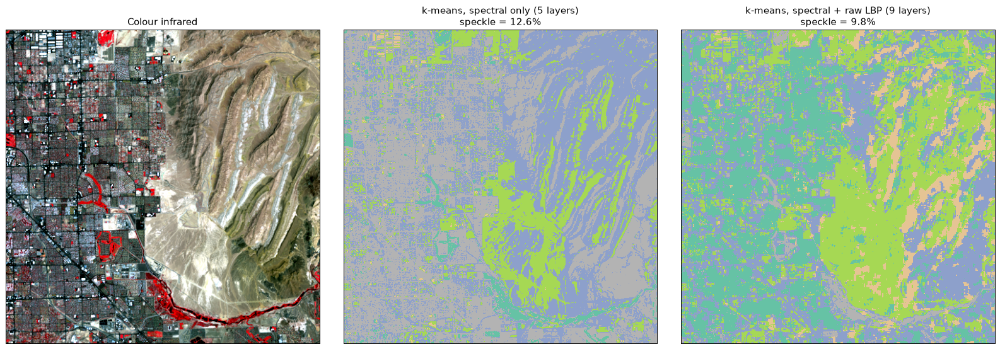

,spectral only,spectral + raw LBP
Urban grid,53%,46%
Alluvial fan,58%,87%
Mountain ridges,66%,63%


In [19]:
# (a) raw LBP at 256 levels, (b) 16-level LBP plus VAR.
print("Raw LBP features (R = 1 and R = 2):")  # first combination
# clustering with the four raw LBP layers
display(compare_clusterings(lp_feats[["LBP uniformity R1", "LBP entropy R1", "LBP uniformity R2", "LBP entropy R2"]], "raw LBP"))

Raw LBP reduces speckle (9.8%) and maps the fan as one cluster (purity 87%), but mixes the city with the
mountain: city purity drops from 53% to 46% and the ridges stay at about 63%.


16-level LBP + VAR:


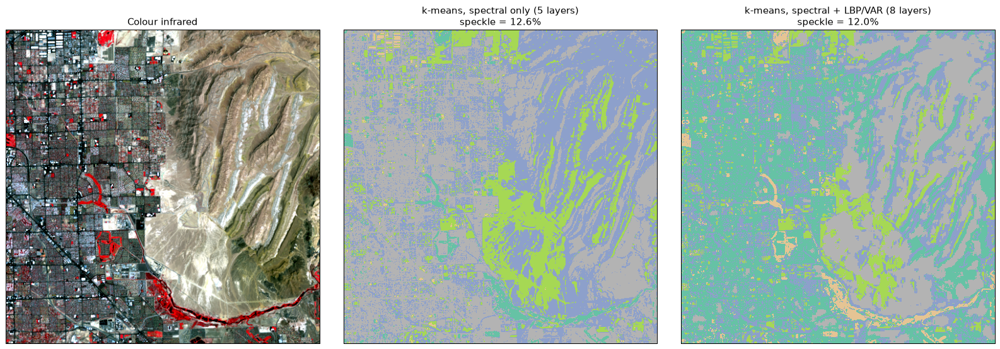

,spectral only,spectral + LBP/VAR
Urban grid,53%,55%
Alluvial fan,58%,66%
Mountain ridges,66%,62%


In [20]:
print("16-level LBP + VAR:")  # second combination
# clustering with the 16-level LBP and VAR
display(compare_clusterings(lp_feats[["LBP entropy 16 levels", "LBP uniformity 16 levels", "log10 VAR"]], "LBP/VAR"))

16-level LBP with VAR changes the clustering only a little (city 55%, fan 66%, ridges 62%; speckle 12.0%).
At 30 m, LBP adds less to the spectral layers than the statistical, transform or model-based texture of
the other notebooks. Its strengths (illumination invariance, micro-pattern detail) pay off on
high-resolution imagery.


In [21]:
OUT = Path("outputs") / "texture"  # output folder for texture rasters
OUT.mkdir(parents=True, exist_ok=True)  # create it if needed
# Dataset -> one multi-band GeoTIFF (one band per feature)
lp_feats.to_array("feature").astype("float32").rio.write_crs(ls.rio.crs).rio.to_raster(OUT / "nir_lbp_texture.tif")
with rasterio.open(OUT / "nir_lbp_texture.tif") as src:  # read the file back to check it
    # number of bands, size and CRS
    print(f"nir_lbp_texture.tif: {src.count} bands, {src.width} x {src.height}, {src.crs}")

nir_lbp_texture.tif: 9 bands, 512 x 512, EPSG:32611


## Summary and exercises

**Key points**

- LBP encodes each pixel's neighbourhood as a binary code of the signs of the neighbour differences.
  Uniform, rotation-invariant codes reduce the vocabulary to P + 2 micro-patterns.
- The texture is the histogram of codes in a window, summarized here by uniformity and entropy.
- LBP is invariant to monotonic brightness changes, which makes it robust across dates, sensors and
  calibration, but it also ignores contrast.
- On smooth surfaces at 30 m, neighbour differences are close to sensor noise, so raw LBP sees noise.
  Coarser quantization (16 gray levels) and the joint LBP/VAR operator restore the distinction between
  smooth and rough surfaces; light Gaussian smoothing alone did not.
- LBP is strongest on high-resolution imagery, where micro-patterns correspond to real objects.

**`geolattice.rsense` functions used:** `rs.read`, `rs.optical.scale`, `rs.viz.plot_rgb`, `rs.viz.plot_raster`,
`tx.lbp_texture`.

**Exercises**

1. Compute LBP on NDVI instead of NIR. Do the city parks and the Las Vegas Wash get different codes?
2. Concatenate the uniform-code histograms for R = 1, 2 and 3 into one 54-bin descriptor per 32 × 32
   tile and cluster the tiles.
3. Compare LBP histograms of this scene with a second Landsat date. Is LBP less sensitive to the
   radiometric difference than GLCM?
4. Find the Gaussian smoothing sigma that best separates the fan from the city in LBP entropy.
5. Apply LBP to a 1 m NAIP or 3 m PlanetScope image of the same area and repeat the LBP code maps.

**References**

- Ojala, T., Pietikäinen, M. and Harwood, D. (1996). A comparative study of texture measures with
  classification based on featured distributions. *Pattern Recognition*, 29(1), 51-59.
- Ojala, T., Pietikäinen, M. and Mäenpää, T. (2002). Multiresolution gray-scale and rotation invariant
  texture classification with local binary patterns. *IEEE TPAMI*, 24(7), 971-987.
- Pietikäinen, M., Hadid, A., Zhao, G. and Ahonen, T. (2011). *Computer Vision Using Local Binary
  Patterns*. Springer.

**Previous:** [Transform-based texture](09_07_02_texture_analysis_of_landsat_imagery_transform_based_spectral_methods.ipynb) ·
**Next:** [Model-based texture](09_07_04_texture_analysis_of_landsat_imagery_model_based_methods.ipynb).
